# Project 16 — Market stress tripwires: weekly check, 7 October 2026
Calibrates the eleven market tripwires (`src/tripwires.py`), back-tests them on past stress episodes, evaluates them as
of the last complete session before 7 Oct 2026, and combines them with the six event tripwires in `data/events.csv`.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT / "src"), str(ROOT.parent)]

import matplotlib.colors as mcolors
import numpy as np
import pandas as pd

import tripwires as TW
from common.plotting import PALETTE, setup, source

plt = setup()
D, FIG = ROOT / "data", ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
ASOF = "2026-10-07"
I, W = TW.load()
T = TW.calibrate(I, W)
C = TW.market_check(ASOF, I, W, T)
E = pd.read_csv(D / "events.csv", index_col=0)
T[["tripwire", "kind", "near", "fire", "share of days at or beyond near", "share of days at or beyond fire", "calibration"]].round(3)

,tripwire,kind,near,fire,share of days at or beyond near,share of days at or beyond fire,calibration
id,,,,,,,
1,Funding: SOFR minus IORB,level,7.000,20.660,0.052,0.010,2018-04-03 – 2025-12-31
2,Funding: Standing Repo Facility usage,level,0.046,4.728,0.051,0.011,2021-07-28 – 2025-12-31
3,Rates volatility: MOVE index,given,117.000,130.000,0.161,0.085,2002-11-12 – 2025-12-31
4,"US 30-year yield, 20-day rise",speed,0.460,0.820,0.051,0.010,1977-03-16 – 2025-12-31
5,"High-yield spread, 20-day widening",speed,0.494,1.014,0.051,0.011,2023-11-06 – 2025-12-31
6,"Leveraged funds' Treasury futures shorts, week...",down,-8.832,-12.886,0.051,0.011,2010-07-27 – 2025-12-30
7,Fed central-bank swap lines outstanding,level,111391.300,475239.740,0.051,0.011,2002-12-18 – 2025-12-31
8,"USD/JPY, 20-day move either way",absspeed,6.213,8.937,0.050,0.010,1971-02-01 – 2025-12-31
9,JGB 30-year yield,given,4.050,4.500,0.000,0.000,1999-09-02 – 2025-12-30


## 1. This week's check

In [2]:
ALL = pd.concat([C[["tripwire", "date", "status"]].assign(type="market"),
                 E[["tripwire", "date", "status"]].assign(type="event")]).sort_index()
SCORE = {"fired": int((ALL["status"] == "FIRED").sum()), "near": int((ALL["status"] == "near").sum()),
         "ok": int((ALL["status"] == "ok").sum()), "no new data": int(ALL["status"].isin(["no data", "no new data"]).sum()),
         "total": len(ALL)}
print(SCORE)
ALL

{'fired': 0, 'near': 4, 'ok': 13, 'no new data': 0, 'total': 17}


,tripwire,date,status,type
id,,,,
1,Funding: SOFR minus IORB,2026-10-06,ok,market
2,Funding: Standing Repo Facility usage,2026-10-06,ok,market
3,Rates volatility: MOVE index,2026-10-06,ok,market
4,"US 30-year yield, 20-day rise",2026-10-06,ok,market
5,"High-yield spread, 20-day widening",2026-10-06,ok,market
6,"Leveraged funds' Treasury futures shorts, week...",2026-09-29,ok,market
7,Fed central-bank swap lines outstanding,2026-09-30,ok,market
8,"USD/JPY, 20-day move either way",2026-10-02,ok,market
9,JGB 30-year yield,2026-10-06,near,market


In [3]:
C.round(3)

,tripwire,date,level,level a week earlier,tested value,near,fire,status
id,,,,,,,,
1,Funding: SOFR minus IORB,2026-10-06,0.000,-2.000,0.000,7.000,20.660,ok
2,Funding: Standing Repo Facility usage,2026-10-06,0.000,0.002,0.000,0.046,4.728,ok
3,Rates volatility: MOVE index,2026-10-06,105.200,106.600,105.200,117.000,130.000,ok
4,"US 30-year yield, 20-day rise",2026-10-06,5.640,5.590,0.390,0.460,0.820,ok
5,"High-yield spread, 20-day widening",2026-10-06,3.030,3.080,0.360,0.494,1.014,ok
6,"Leveraged funds' Treasury futures shorts, week...",2026-09-29,1078.662,1090.146,-1.053,-8.832,-12.886,ok
7,Fed central-bank swap lines outstanding,2026-09-30,207.000,72.000,207.000,111391.300,475239.740,ok
8,"USD/JPY, 20-day move either way",2026-10-02,157.810,157.180,1.557,6.213,8.937,ok
9,JGB 30-year yield,2026-10-06,4.168,4.126,4.168,4.050,4.500,near


## 2. Distance to trigger
For each market tripwire: where the tested value sits between the median of its calibration window (0) and the fire
trigger (1). The near line is marked for each.

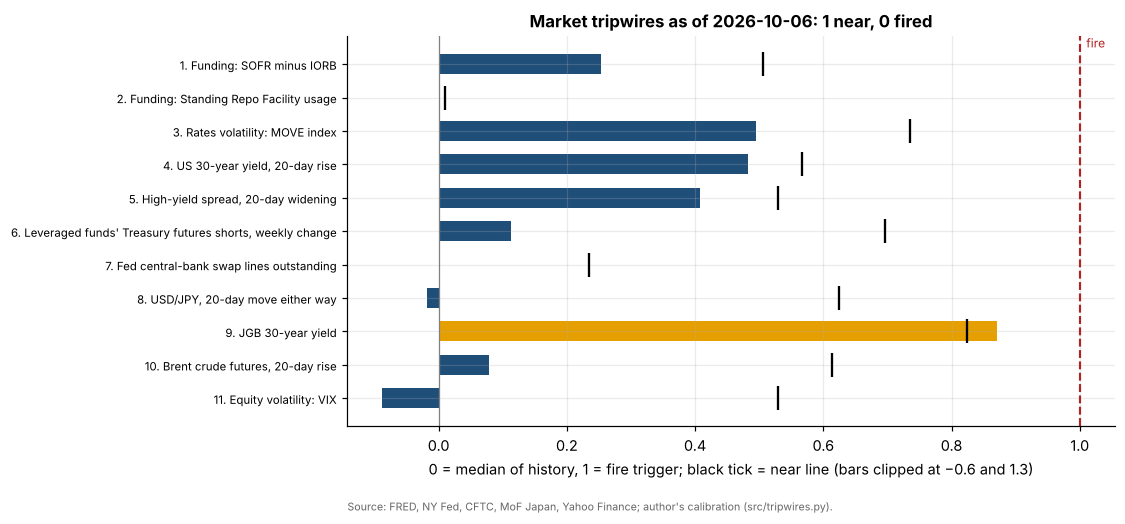

,value,near
1,0.25,0.51
2,0.00,0.01
3,0.49,0.74
4,0.48,0.57
5,0.41,0.53
6,0.11,0.70
7,0.00,0.23
8,-0.02,0.62
9,0.87,0.82
10,0.08,0.61


In [4]:
pos = {}
for tid, r in T.iterrows():
    x = TW.signal(I, W, r["series"], r["kind"]).loc[:TW.CAL_END]
    med = x.median()
    v = C.loc[tid, "tested value"]
    pos[tid] = {"value": (v - med) / (r["fire"] - med), "near": (r["near"] - med) / (r["fire"] - med)}
POS = pd.DataFrame(pos).T
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(POS))[::-1]
col = [("#B22222" if C.loc[i, "status"] == "FIRED" else "#E69F00" if C.loc[i, "status"] == "near" else PALETTE[0]) for i in POS.index]
ax.barh(y, POS["value"].clip(-0.6, 1.3), color=col, height=0.6)
ax.scatter(POS["near"], y, marker="|", s=250, color="black", zorder=3)
ax.axvline(1, color="#B22222", lw=1.4, ls="--"); ax.text(1.01, y[0] + 0.5, "fire", color="#B22222", fontsize=8)
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(y, [f"{i}. {T.loc[i, 'tripwire']}" for i in POS.index], fontsize=7.5)
ax.set_xlabel("0 = median of history, 1 = fire trigger; black tick = near line (bars clipped at −0.6 and 1.3)")
ax.set_title(f"Market tripwires as of {C['date'].max()}: {int((C['status'] == 'near').sum())} near, "
             f"{int((C['status'] == 'FIRED').sum())} fired")
source(ax, "Source: FRED, NY Fed, CFTC, MoF Japan, Yahoo Finance; author's calibration (src/tripwires.py).")
fig.savefig(FIG / "fig_distance.png"); plt.show()
POS.round(2)

## 3. Back-test: did the tripwires fire in past stress episodes?
For each episode: the highest status of each tripwire over the two weeks ending on the date. Tripwires whose data did
not yet exist are excluded (HY spread history starts in Oct 2023 on FRED; the SRF in Jul 2021; SOFR in Apr 2018).

In [5]:
H = TW.history(I, W, T, "2007-01-01")
EP = {"Bear Stearns": "2008-03-14", "Lehman": "2008-09-15", "Oct 2008 crash": "2008-10-10", "US downgrade": "2011-08-08",
      "Taper tantrum": "2013-06-24", "China devaluation": "2015-08-24", "Volmageddon": "2018-02-05", "Repo spike": "2019-09-17",
      "Covid": "2020-03-16", "UK gilt crisis": "2022-09-28", "SVB": "2023-03-13", "Yen carry unwind": "2024-08-05",
      "US tariffs": "2025-04-08"}
bt = {}
for k, d in EP.items():
    m = H.loc[:d].tail(10).max()
    bt[f"{k} ({d})"] = {"Fired": int((m == 2).sum()), "Near": int((m == 1).sum()), "Tripwires with data": int(m.notna().sum()),
                        "Which fired": ", ".join(str(i) for i in m.index[m == 2]) or "–"}
BT = pd.DataFrame(bt).T
cnt = (H == 2).sum(axis=1)
FREQ = {"Business days since 2007": len(H), "Share with at least one fired": float((cnt >= 1).mean()),
        "Share with three or more fired": float((cnt >= 3).mean())}
print(FREQ)
BT

{'Business days since 2007': 5158, 'Share with at least one fired': 0.12718107793718494, 'Share with three or more fired': 0.009305932531989143}


,Fired,Near,Tripwires with data,Which fired
Bear Stearns (2008-03-14),1,2,7,3
Lehman (2008-09-15),1,0,7,3
Oct 2008 crash (2008-10-10),2,2,7,"3, 11"
US downgrade (2011-08-08),1,2,8,11
Taper tantrum (2013-06-24),0,1,8,–
China devaluation (2015-08-24),0,1,8,–
Volmageddon (2018-02-05),0,1,8,–
Repo spike (2019-09-17),1,1,9,1
Covid (2020-03-16),2,2,9,"3, 11"
UK gilt crisis (2022-09-28),1,1,10,3


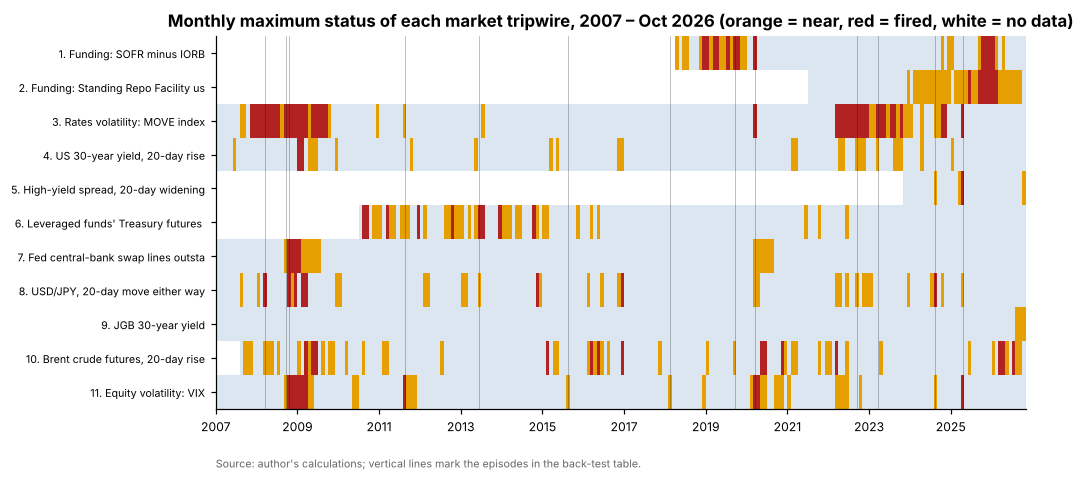

In [6]:
M = H.resample("ME").max()
fig, ax = plt.subplots(figsize=(9.5, 4.4))
cmap = mcolors.ListedColormap(["#DCE6F0", "#E69F00", "#B22222"])
ax.imshow(M.T.values, aspect="auto", cmap=cmap, vmin=0, vmax=2, interpolation="nearest",
          extent=[0, len(M), len(M.columns) - 0.5, -0.5])
yrs = [i for i, d in enumerate(M.index) if d.month == 1 and d.year % 2 == 1]
ax.set_xticks(yrs, [M.index[i].year for i in yrs], fontsize=8)
ax.set_yticks(range(len(M.columns)), [f"{i}. {T.loc[i, 'tripwire'][:34]}" for i in M.columns], fontsize=7)
ax.grid(False)
ax.set_title("Monthly maximum status of each market tripwire, 2007 – Oct 2026 (orange = near, red = fired, white = no data)")
for nm, d in EP.items():
    j = M.index.searchsorted(pd.Timestamp(d))
    ax.axvline(j + 0.5, color="black", lw=0.4, alpha=0.4)
source(ax, "Source: author's calculations; vertical lines mark the episodes in the back-test table.")
fig.savefig(FIG / "fig_history.png"); plt.show()

## 4. Slow versus fast gauges since August 2026

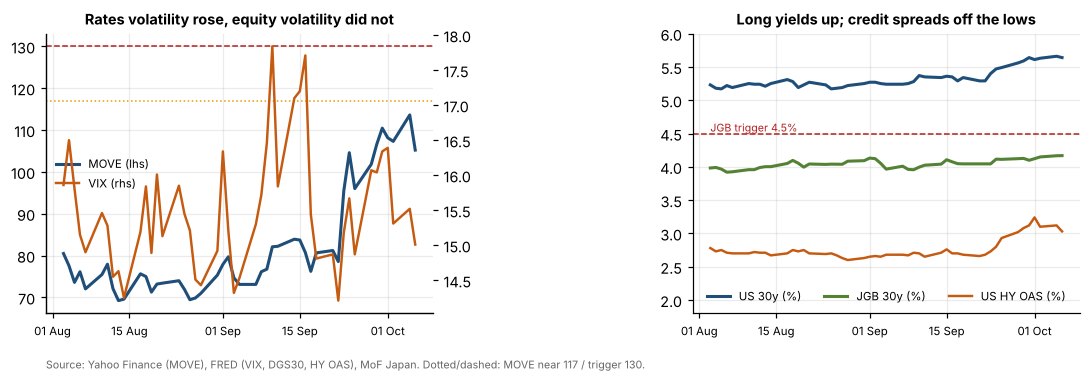

In [7]:
z = I.loc["2026-08-01":"2026-10-06", ["MOVE", "UST 30y (%)", "JGB 30y (%)", "VIX", "HY OAS (%)"]].ffill()
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].plot(z.index, z["MOVE"], color=PALETTE[0], lw=2, label="MOVE (lhs)")
axs[0].axhline(117, color="#E69F00", ls=":", lw=1); axs[0].axhline(130, color="#B22222", ls="--", lw=1)
a2 = axs[0].twinx(); a2.grid(False); a2.plot(z.index, z["VIX"], color=PALETTE[1], lw=1.6, label="VIX (rhs)")
axs[0].set_title("Rates volatility rose, equity volatility did not", fontsize=9.5)
h1, l1 = axs[0].get_legend_handles_labels(); h2, l2 = a2.get_legend_handles_labels(); axs[0].legend(h1 + h2, l1 + l2, fontsize=7.5, loc="center left")
axs[1].plot(z.index, z["UST 30y (%)"], color=PALETTE[0], lw=2, label="US 30y (%)")
axs[1].plot(z.index, z["JGB 30y (%)"], color=PALETTE[2], lw=2, label="JGB 30y (%)")
axs[1].plot(z.index, z["HY OAS (%)"], color=PALETTE[1], lw=1.6, label="US HY OAS (%)")
axs[1].axhline(4.5, color="#B22222", ls="--", lw=1); axs[1].text(z.index[0], 4.53, "JGB trigger 4.5%", fontsize=7, color="#B22222")
axs[1].set_title("Long yields up; credit spreads off the lows", fontsize=9.5)
axs[1].set_ylim(1.8, 6.0); axs[1].legend(fontsize=7.5, loc="lower center", ncol=3)
import matplotlib.dates as mdates
for a in axs:
    a.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 15])); a.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); a.tick_params(axis="x", labelsize=7.5)
axs[0].annotate("Source: Yahoo Finance (MOVE), FRED (VIX, DGS30, HY OAS), MoF Japan. Dotted/dashed: MOVE near 117 / trigger 130.",
                xy=(0, -0.16), xycoords="axes fraction", fontsize=7, color="#666666", va="top")
fig.tight_layout(); fig.savefig(FIG / "fig_slow_fast.png"); plt.show()

## Save

In [8]:
T.to_csv(D / "thresholds.csv"); C.to_csv(D / f"check_{ASOF}.csv"); BT.to_csv(D / "backtest_episodes.csv")
H.to_csv(D / "status_history_daily.csv"); ALL.to_csv(D / f"scorecard_{ASOF}.csv")
json.dump({"asof": ASOF, "score": SCORE, "frequency": FREQ}, open(D / "summary.json", "w"), indent=2)